In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Polygon

In [2]:
load_folder = 'edge_spen'

In [3]:
pos_list = np.load(load_folder + '/positions_gif.npy')
pher_list = np.load(load_folder + '/pheromones_gif.npy')

In [4]:
Lx, Ly = 32, 32
t_transient = 0
n = 300

In [5]:
pos_list = pos_list[t_transient:]
pher_list = pher_list[t_transient:]

In [6]:
pos_list.shape

(1000, 330, 2)

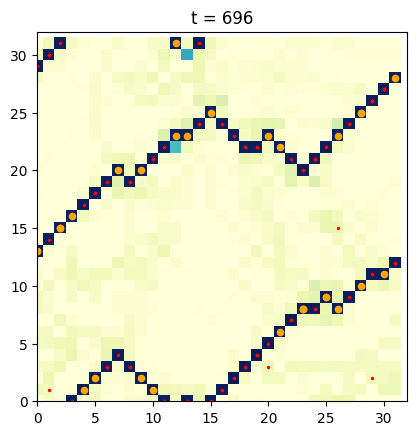

In [8]:
# Settings
cc_animation = True

if cc_animation:
    num_frames = len(pos_list)-300
    frame_skip = 3 # Skip every 2nd frame for speed
    fig, ax = plt.subplots()
    ax.set_xlim(0, Lx)
    ax.set_ylim(0, Ly)

    # Precompute data
    '''precomputed_data = [
        [
            [
                (pos[0] + head[0] / 10, pos[1] + head[1] / 10),
                (pos[0] - head[0] / 10 + perp_head[0] / 20, pos[1] - head[1] / 10 + perp_head[1] / 20),
                (pos[0] - head[0] / 10 - perp_head[0] / 20, pos[1] - head[1] / 10 - perp_head[1] / 20),
            ]
            for pos, head, perp_head in zip(
                positions,
                heads,
                [np.array([-h[1], h[0]]) for h in heads],
            )
        ]
        for positions, heads in zip(pos_list, head_list)
    ]'''

    def animate(i):
        
        frame_idx = i * frame_skip
        if frame_idx >= num_frames:
            frame_idx = num_frames - 1
            
        ax.clear()
        ax.imshow(np.log10(pher_list[frame_idx] + 1e-2), cmap='YlGnBu')
        ax.set_xlim(0, Lx)
        ax.set_ylim(0, Ly)
        ax.set_title(f"t = {frame_idx}")
        
        '''for vertices in precomputed_data[frame_idx]:
            polygon = Polygon(vertices, closed=True, color='red')
            ax.add_patch(polygon)'''
        
        ax.scatter(np.array(pos_list)[frame_idx, :n, 1], np.array(pos_list)[frame_idx, :n, 0], c='red', s=2)

        ax.scatter(np.array(pos_list)[frame_idx, n:, 1], np.array(pos_list)[frame_idx, n:, 0], c='orange', s=20)
        # ax.scatter(np.array(pos_list)[frame_idx, -10:, 0], np.array(pos_list)[frame_idx, -10:, 1], c='black', marker='x', s=1)
        

    ani = animation.FuncAnimation(
        fig, animate, repeat=True, frames=num_frames // frame_skip, interval=1
    )

    from matplotlib import animation

    writer = animation.PillowWriter(fps=15)
    ani.save("RLants.gif", writer=writer)


    # Optional for display:
    plt.show()

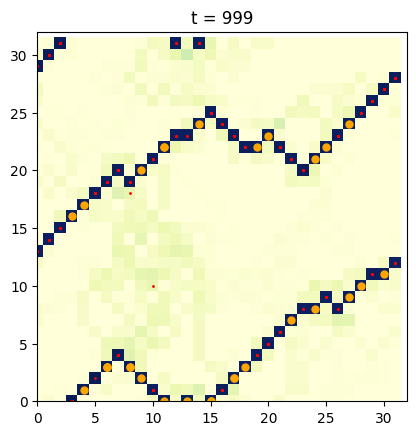

In [10]:
# Set up the plot
fig, ax = plt.subplots()
ax.set_xlim(0, Lx)
ax.set_ylim(0, Ly)

# Compute the last frame index
last_frame_idx = len(pos_list) - 1

# Render the last frame
ax.imshow(np.log10(pher_list[last_frame_idx] + 1e-2), cmap='YlGnBu')
ax.set_xlim(0, Lx)
ax.set_ylim(0, Ly)
ax.set_title(f"t = {last_frame_idx}")

# Plot the agents
ax.scatter(
    np.array(pos_list)[last_frame_idx, :n, 1],
    np.array(pos_list)[last_frame_idx, :n, 0],
    c='red',
    s=1
)
ax.scatter(
    np.array(pos_list)[last_frame_idx, n:, 1],
    np.array(pos_list)[last_frame_idx, n:, 0],
    c='orange',
    s=25
)

# Save the last frame as a PNG
plt.savefig("last_frame.png", dpi=300)
plt.show()
plt.close(fig)
